In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
import statistics
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier as RB
#from sklearn.decomposition import KernelPCA
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE as SM
from sklearn.ensemble import RandomForestRegressor as RF,GradientBoostingRegressor as GB,ExtraTreesClassifier as ET
from sklearn.metrics import f1_score
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.neural_network import MLPClassifier as MP

In [ ]:
df=pd.read_csv('data set.csv')

In [ ]:
df.head()

,1/1/2014,1/2/2014,1/3/2014,1/4/2014,1/5/2014,1/6/2014,1/7/2014,1/8/2014,1/9/2014,1/10/2014,...,10/24/2016,10/25/2016,10/26/2016,10/27/2016,10/28/2016,10/29/2016,10/30/2016,10/31/2016,CONS_NO,FLAG
0,0.0,0.0,0.01,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,0.02,0.06,0.58,0.89,0.35,0.38,0.70,0.25,0387DD8A07E07FDA6271170F86AD9151,1
1,0.0,0.0,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,17.13,14.32,16.37,26.33,19.06,17.38,13.94,14.14,01D6177B5D4FFE0CABA9EF17DAFC2B84,1
2,0.0,0.0,0.00,0.0,0.0,4.98,9.87,11.29,13.44,11.34,...,NaN,1.43,2.22,2.41,3.48,2.89,1.88,1.16,4B75AC4F2D8434CFF62DB64D0BB43103,1
3,0.0,0.0,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,20.98,18.47,15.50,14.80,19.28,16.10,17.51,16.67,B32AC8CC6D5D805AC053557AB05F5343,1
4,0.0,0.0,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,0.61,1.33,0.55,1.62,1.53,2.10,1.16,2.13,EDFC78B07BA2908B3395C4EB2304665E,1


In [ ]:
print(f"Lignes: {df.shape[0]}, Colonnes: {df.shape[1]}")

Lignes: 42372, Colonnes: 1036


In [ ]:
print(df.dtypes.value_counts())


float64    1034
object        1
int64         1
Name: count, dtype: int64


In [ ]:
print(" Distribution de FLAG (Variable Cible):")
print(df['FLAG'].value_counts())
print("\n Proportion:")
print(df['FLAG'].value_counts(normalize=True))

 Distribution de FLAG (Variable Cible):
FLAG
0    38757
1     3615
Name: count, dtype: int64

 Proportion:
FLAG
0    0.914684
1    0.085316
Name: proportion, dtype: float64


## Etape 1

### Exploration et Visualisation Initiale

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import warnings
warnings.filterwarnings('ignore')

# Configuration des graphiques
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

print("Bibliothèques importées avec succès!")

Bibliothèques importées avec succès!


In [ ]:

print(" INFORMATIONS GÉNÉRALES")
print(f"Nombre de clients: {df.shape[0]:,}")
print(f"Nombre de jours: {df.shape[1] - 2}")  # -2 pour CONS_NO et FLAG
print(f"\n DISTRIBUTION DES CLASSES:")
print(df['FLAG'].value_counts())
print(f"\n PROPORTION:")
print(f"Clients normaux: {(df['FLAG']==0).sum() / len(df) * 100:.2f}%")
print(f"Clients fraudeurs: {(df['FLAG']==1).sum() / len(df) * 100:.2f}%")
print(f"\n RATIO DE DÉSÉQUILIBRE: 1:{(df['FLAG']==0).sum() / (df['FLAG']==1).sum():.1f}")

 INFORMATIONS GÉNÉRALES
Nombre de clients: 42,372
Nombre de jours: 1034

 DISTRIBUTION DES CLASSES:
FLAG
0    38757
1     3615
Name: count, dtype: int64

 PROPORTION:
Clients normaux: 91.47%
Clients fraudeurs: 8.53%

 RATIO DE DÉSÉQUILIBRE: 1:10.7


### Analyse des Valeurs Manquantes

In [ ]:
#  Détection des valeurs manquantes
# Séparer les colonnes de dates
date_columns = [col for col in df.columns if col not in ['CONS_NO', 'FLAG']]

In [ ]:
print(" ANALYSE DES VALEURS MANQUANTES\n")
print(f"Nombre total de valeurs: {df[date_columns].size:,}")
print(f"Valeurs manquantes: {df[date_columns].isnull().sum().sum():,}")
print(f"Pourcentage: {df[date_columns].isnull().sum().sum() / df[date_columns].size * 100:.4f}%")

 ANALYSE DES VALEURS MANQUANTES

Nombre total de valeurs: 43,812,648
Valeurs manquantes: 11,233,528
Pourcentage: 25.6399%


In [ ]:
# Clients avec le plus de valeurs manquantes
missing_per_client = df[date_columns].isnull().sum(axis=1)
print(f"\n Top 5 clients avec le plus de NaN:")
print(missing_per_client.nlargest(5))



 Top 5 clients avec le plus de NaN:
26036    1034
26154    1034
27117    1034
40593    1034
42225    1034
dtype: int64


In [ ]:
# Jours avec le plus de valeurs manquantes
missing_per_day = df[date_columns].isnull().sum()
print(f"\n Jours avec des NaN:")
print(missing_per_day[missing_per_day > 0].sort_values(ascending=False).head(10))


 Jours avec des NaN:
10/3/2014    42357
3/19/2014    21505
2/28/2014    20985
3/4/2014     20820
3/3/2014     20806
4/19/2014    20633
2/20/2014    20536
2/23/2014    20494
2/24/2014    20326
3/2/2014     20224
dtype: int64


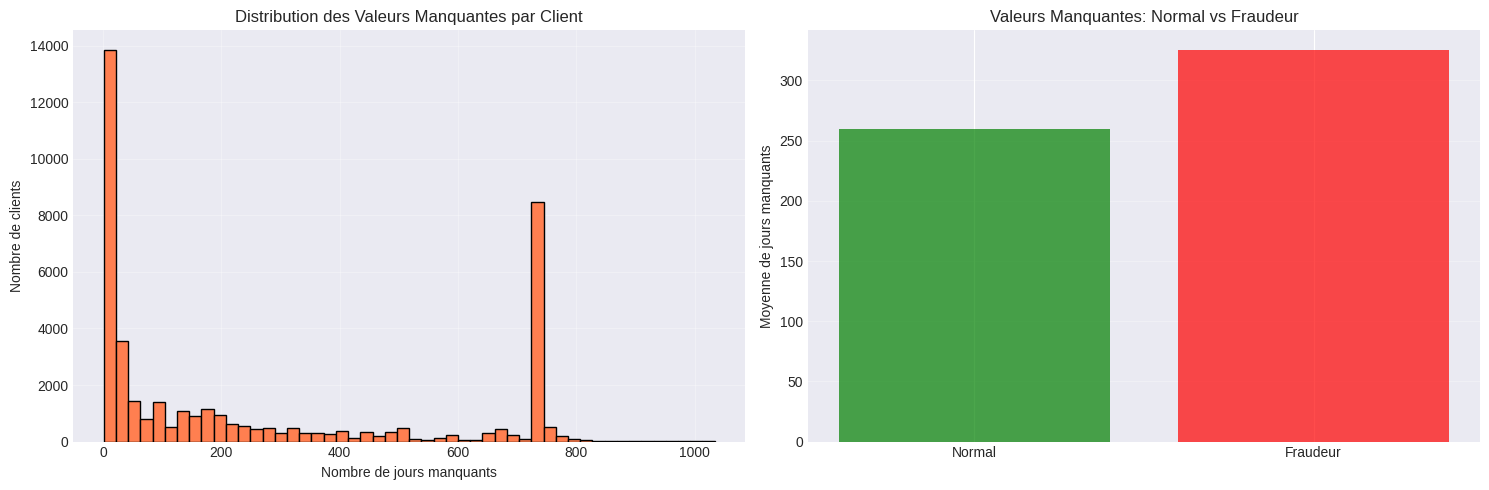

 Moyenne de NaN - Normaux: 259.50 jours
 Moyenne de NaN - Fraudeurs: 325.39 jours


In [ ]:
# Visualisation des valeurs manquantes
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Graphique 1: Distribution des NaN par client
axes[0].hist(missing_per_client, bins=50, color='coral', edgecolor='black')
axes[0].set_xlabel('Nombre de jours manquants')
axes[0].set_ylabel('Nombre de clients')
axes[0].set_title('Distribution des Valeurs Manquantes par Client')
axes[0].grid(True, alpha=0.3)


# Graphique 2: Comparaison Fraudeurs vs Normaux
fraud_missing = df[df['FLAG']==1][date_columns].isnull().sum(axis=1).mean()
normal_missing = df[df['FLAG']==0][date_columns].isnull().sum(axis=1).mean()
axes[1].bar(['Normal', 'Fraudeur'], [normal_missing, fraud_missing],
            color=['green', 'red'], alpha=0.7)
axes[1].set_ylabel('Moyenne de jours manquants')
axes[1].set_title('Valeurs Manquantes: Normal vs Fraudeur')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


print(f" Moyenne de NaN - Normaux: {normal_missing:.2f} jours")
print(f" Moyenne de NaN - Fraudeurs: {fraud_missing:.2f} jours")



### Traitement des Valeurs Manquantes

In [ ]:
#  Imputation des valeurs manquantes
print(" TRAITEMENT DES VALEURS MANQUANTES\n")

# Stratégie: Remplir les NaN par 0 (hypothèse: pas de consommation enregistrée = 0)
df_clean = df.copy()
df_clean[date_columns] = df_clean[date_columns].fillna(0)

 TRAITEMENT DES VALEURS MANQUANTES



In [ ]:
print(f" Valeurs manquantes après imputation: {df_clean[date_columns].isnull().sum().sum()}")


 Valeurs manquantes après imputation: 0


In [ ]:
print("\n Statistiques après imputation:")
print(df_clean[date_columns].describe())


 Statistiques après imputation:
           1/1/2014      1/2/2014      1/3/2014      1/4/2014      1/5/2014  \
count  42372.000000  42372.000000  42372.000000  42372.000000  42372.000000   
mean       4.376833      4.309258      4.094001      4.419585      4.515401   
std       26.897175     23.760455     24.616240     38.847729     32.601298   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.000000      0.000000      0.000000      0.000000      0.000000   
50%        0.000000      0.000000      0.000000      0.000000      0.000000   
75%        5.080000      5.062500      4.700000      4.970000      5.282500   
max     3318.000000   2500.000000   2674.000000   5670.000000   4854.000000   

           1/6/2014      1/7/2014      1/8/2014      1/9/2014     1/10/2014  \
count  42372.000000  42372.000000  42372.000000  42372.000000  42372.000000   
mean       4.238212      4.441079      4.195981      4.253377      4.252745   
std       29.56517

### Feature Engineeringe

In [ ]:
#  Extraction de features statistiques
print(" CRÉATION DE NOUVELLES FEATURES\n")

# Features statistiques de base
df_features = pd.DataFrame()
df_features['CONS_NO'] = df_clean['CONS_NO']
df_features['FLAG'] = df_clean['FLAG']
consumption_data = df_clean[date_columns].values

 CRÉATION DE NOUVELLES FEATURES



In [ ]:
# 1. Statistiques de base
df_features['mean_consumption'] = np.mean(consumption_data, axis=1)
df_features['std_consumption'] = np.std(consumption_data, axis=1)
df_features['median_consumption'] = np.median(consumption_data, axis=1)
df_features['min_consumption'] = np.min(consumption_data, axis=1)
df_features['max_consumption'] = np.max(consumption_data, axis=1)
df_features['total_consumption'] = np.sum(consumption_data, axis=1)


In [ ]:
df_features['cv'] = df_features['std_consumption'] / (df_features['mean_consumption'] + 1e-10)  # Coefficient de variation
df_features['range_consumption'] = df_features['max_consumption'] - df_features['min_consumption']


In [ ]:
# 3. Percentiles
df_features['q25'] = np.percentile(consumption_data, 25, axis=1)
df_features['q75'] = np.percentile(consumption_data, 75, axis=1)
df_features['iqr'] = df_features['q75'] - df_features['q25']

In [ ]:
df_features['zero_days'] = np.sum(consumption_data == 0, axis=1)
df_features['zero_ratio'] = df_features['zero_days'] / len(date_columns)

In [ ]:
print(f"{len(df_features.columns) - 2} features créées!")
print("\n Aperçu des nouvelles features:")
print(df_features.head())

13 features créées!

 Aperçu des nouvelles features:
                            CONS_NO  FLAG  mean_consumption  std_consumption  \
0  0387DD8A07E07FDA6271170F86AD9151     1          0.944130         3.094565   
1  01D6177B5D4FFE0CABA9EF17DAFC2B84     1          3.768801         6.666713   
2  4B75AC4F2D8434CFF62DB64D0BB43103     1          5.740000         9.368963   
3  B32AC8CC6D5D805AC053557AB05F5343     1          3.578627         7.943032   
4  EDFC78B07BA2908B3395C4EB2304665E     1         23.225967        49.519538   

   median_consumption  min_consumption  max_consumption  total_consumption  \
0               0.000              0.0            18.29             976.23   
1               0.550              0.0            44.57            3896.94   
2               1.875              0.0            79.71            5935.16   
3               0.000              0.0            40.98            3700.30   
4               0.000              0.0           399.40           24015.65  

In [ ]:
#  Features temporelles avancées
print("📅 FEATURES TEMPORELLES AVANCÉES\n")

# 5. Tendance (régression linéaire simple)
def calculate_trend(row):
    x = np.arange(len(row))
    if np.std(row) == 0:
        return 0
    return np.polyfit(x, row, 1)[0]  # Pente de la droite

df_features['trend'] = np.apply_along_axis(calculate_trend, 1, consumption_data)

# 6. Pics de consommation
df_features['n_peaks'] = np.sum(consumption_data > (df_features['mean_consumption'].values.reshape(-1, 1) +
                                                      2 * df_features['std_consumption'].values.reshape(-1, 1)), axis=1)


📅 FEATURES TEMPORELLES AVANCÉES



In [ ]:
# 7. Jours consécutifs sans consommation
def max_consecutive_zeros(row):
    max_zeros = 0
    current_zeros = 0
    for val in row:
        if val == 0:
            current_zeros += 1
            max_zeros = max(max_zeros, current_zeros)
        else:
            current_zeros = 0
    return max_zeros

df_features['max_consecutive_zeros'] = np.apply_along_axis(max_consecutive_zeros, 1, consumption_data)


In [ ]:
# 8. Skewness et Kurtosis (asymétrie et aplatissement)
from scipy.stats import skew, kurtosis
df_features['skewness'] = skew(consumption_data, axis=1)
df_features['kurtosis'] = kurtosis(consumption_data, axis=1)

In [ ]:
print(f" Total features: {len(df_features.columns) - 2}")
print("\n Toutes les features:")
print(df_features.columns.tolist())

 Total features: 18

 Toutes les features:
['CONS_NO', 'FLAG', 'mean_consumption', 'std_consumption', 'median_consumption', 'min_consumption', 'max_consumption', 'total_consumption', 'cv', 'range_consumption', 'q25', 'q75', 'iqr', 'zero_days', 'zero_ratio', 'trend', 'n_peaks', 'max_consecutive_zeros', 'skewness', 'kurtosis']


###  Analyse Exploratoire des Features

In [ ]:
# Cellule 8 : Comparaison Fraudeurs vs Normaux
print(" COMPARAISON DES PROFILS: FRAUDEURS VS NORMAUX\n")
# Sélectionner les features numériques (sans CONS_NO et FLAG)
feature_cols = [col for col in df_features.columns if col not in ['CONS_NO', 'FLAG']]

# Statistiques par groupe
fraud_stats = df_features[df_features['FLAG']==1][feature_cols].describe().T
normal_stats = df_features[df_features['FLAG']==0][feature_cols].describe().T

comparison = pd.DataFrame({
    'Fraudeur_Mean': fraud_stats['mean'],
    'Normal_Mean': normal_stats['mean'],
    'Difference_%': ((fraud_stats['mean'] - normal_stats['mean']) / normal_stats['mean'] * 100).round(2)
})

print(comparison.sort_values('Difference_%', key=abs, ascending=False).head(10))

 COMPARAISON DES PROFILS: FRAUDEURS VS NORMAUX

                    Fraudeur_Mean  Normal_Mean  Difference_%
trend                    0.023712     0.003918        505.22
iqr                     21.366508     5.164357        313.73
std_consumption         30.123371     8.042186        274.57
q75                     26.525475     7.821370        239.14
mean_consumption        18.867272     5.767258        227.14
total_consumption    19508.759418  5963.344652        227.14
max_consumption        427.572383   137.402956        211.18
range_consumption      427.572383   137.402956        211.18
median_consumption      11.595393     4.355412        166.23
q25                      5.158967     2.657013         94.16


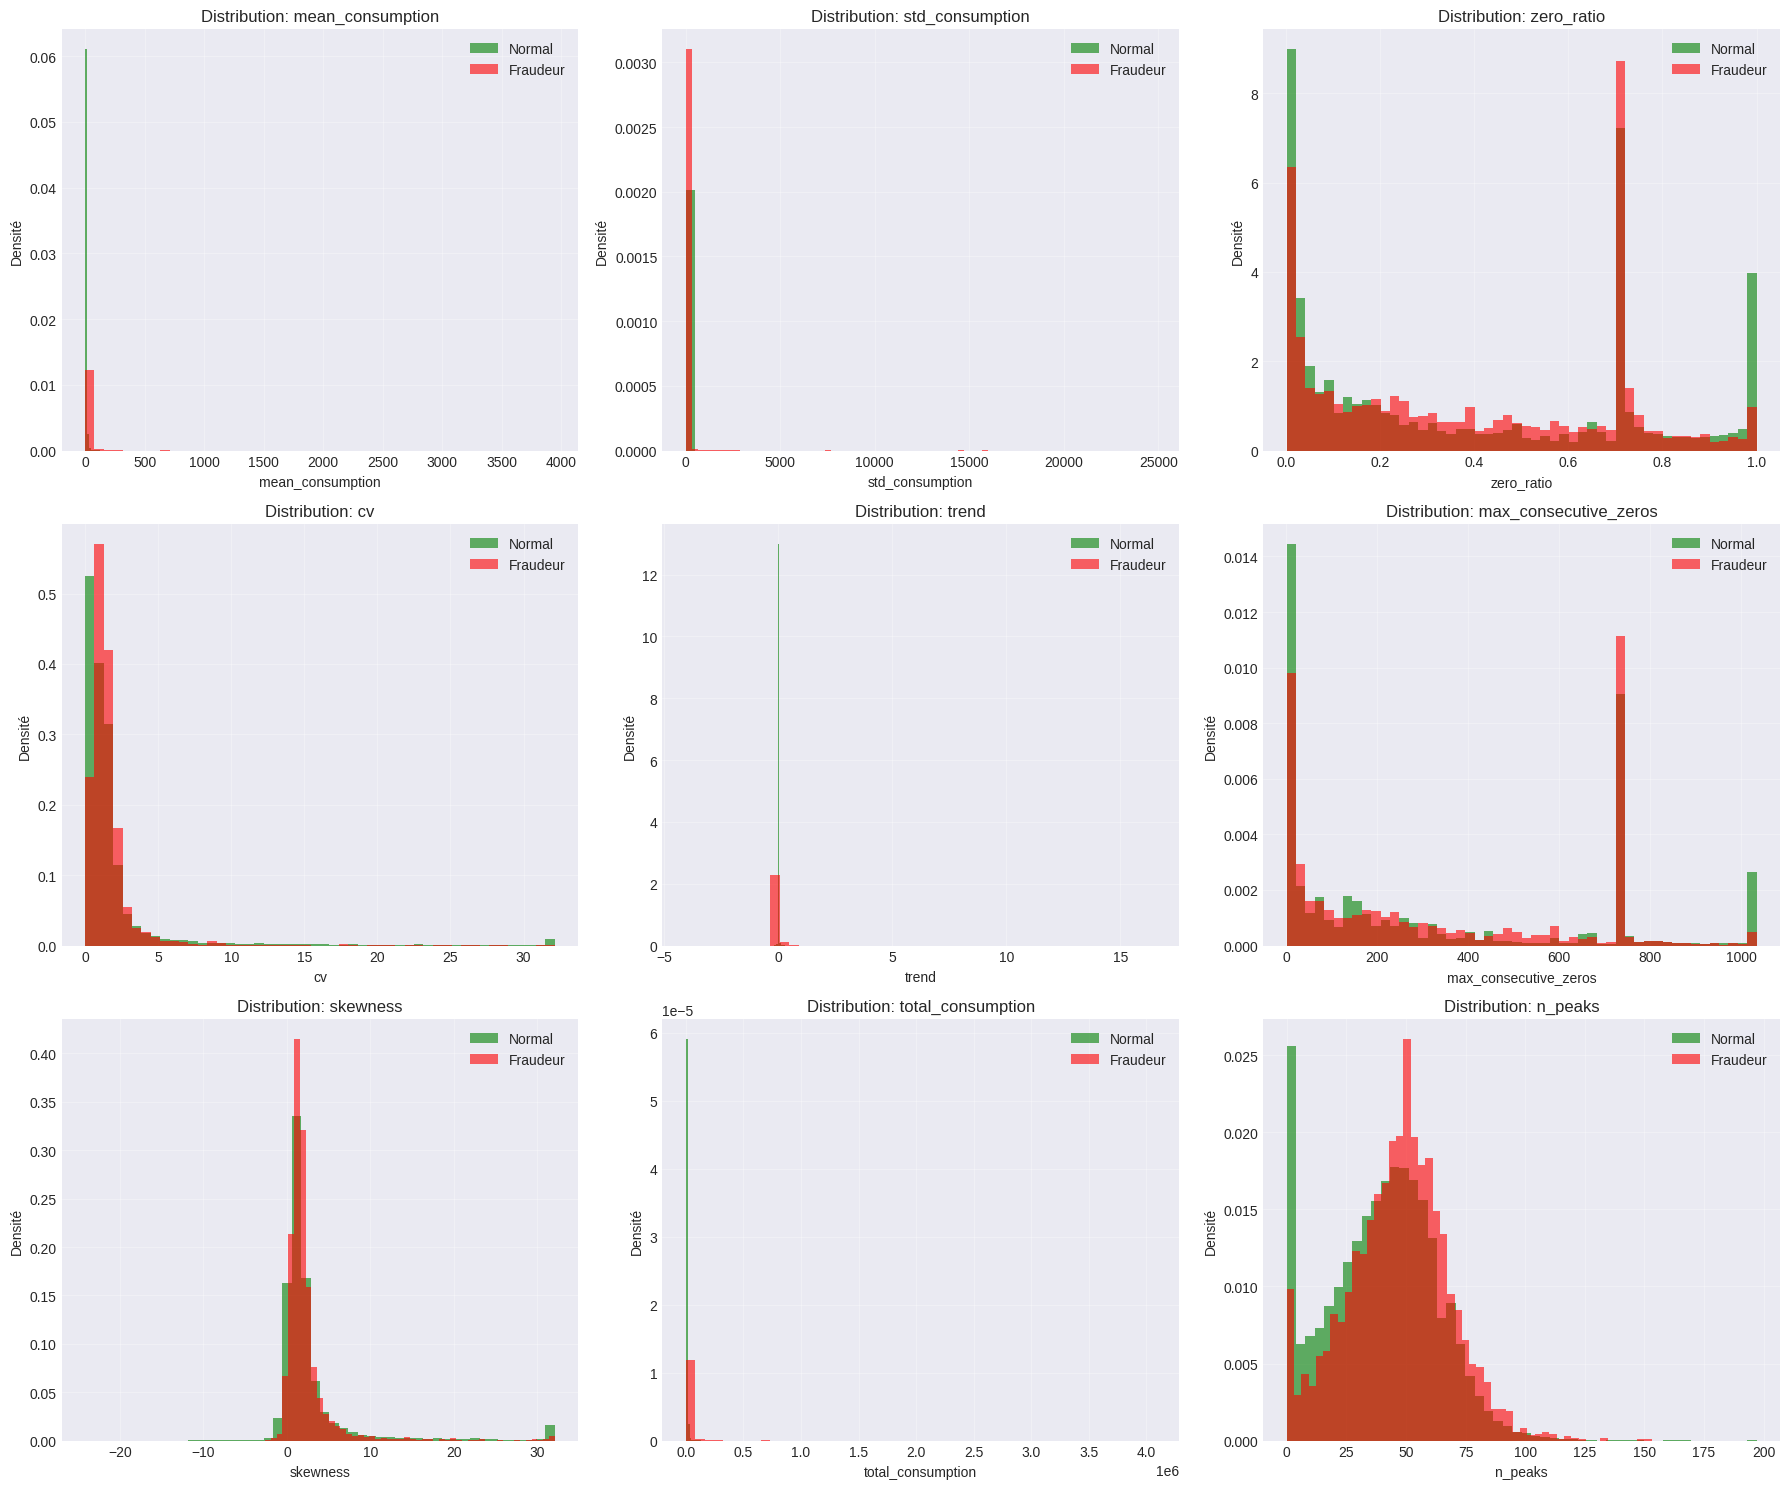

In [ ]:
#  Visualisation des distributions
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.ravel()

# Top 9 features les plus discriminantes
top_features = ['mean_consumption', 'std_consumption', 'zero_ratio', 'cv',
                'trend', 'max_consecutive_zeros', 'skewness', 'total_consumption', 'n_peaks']

for idx, feature in enumerate(top_features[:9]):
    axes[idx].hist(df_features[df_features['FLAG']==0][feature], bins=50, alpha=0.6,
                   label='Normal', color='green', density=True)
    axes[idx].hist(df_features[df_features['FLAG']==1][feature], bins=50, alpha=0.6,
                   label='Fraudeur', color='red', density=True)
    axes[idx].set_xlabel(feature)
    axes[idx].set_ylabel('Densité')
    axes[idx].set_title(f'Distribution: {feature}')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## ETAPE 2 " Normalisation des données "

### Analyse de corrélation (avant normalisation)

🔗 ANALYSE DE CORRÉLATION ENTRE FEATURES



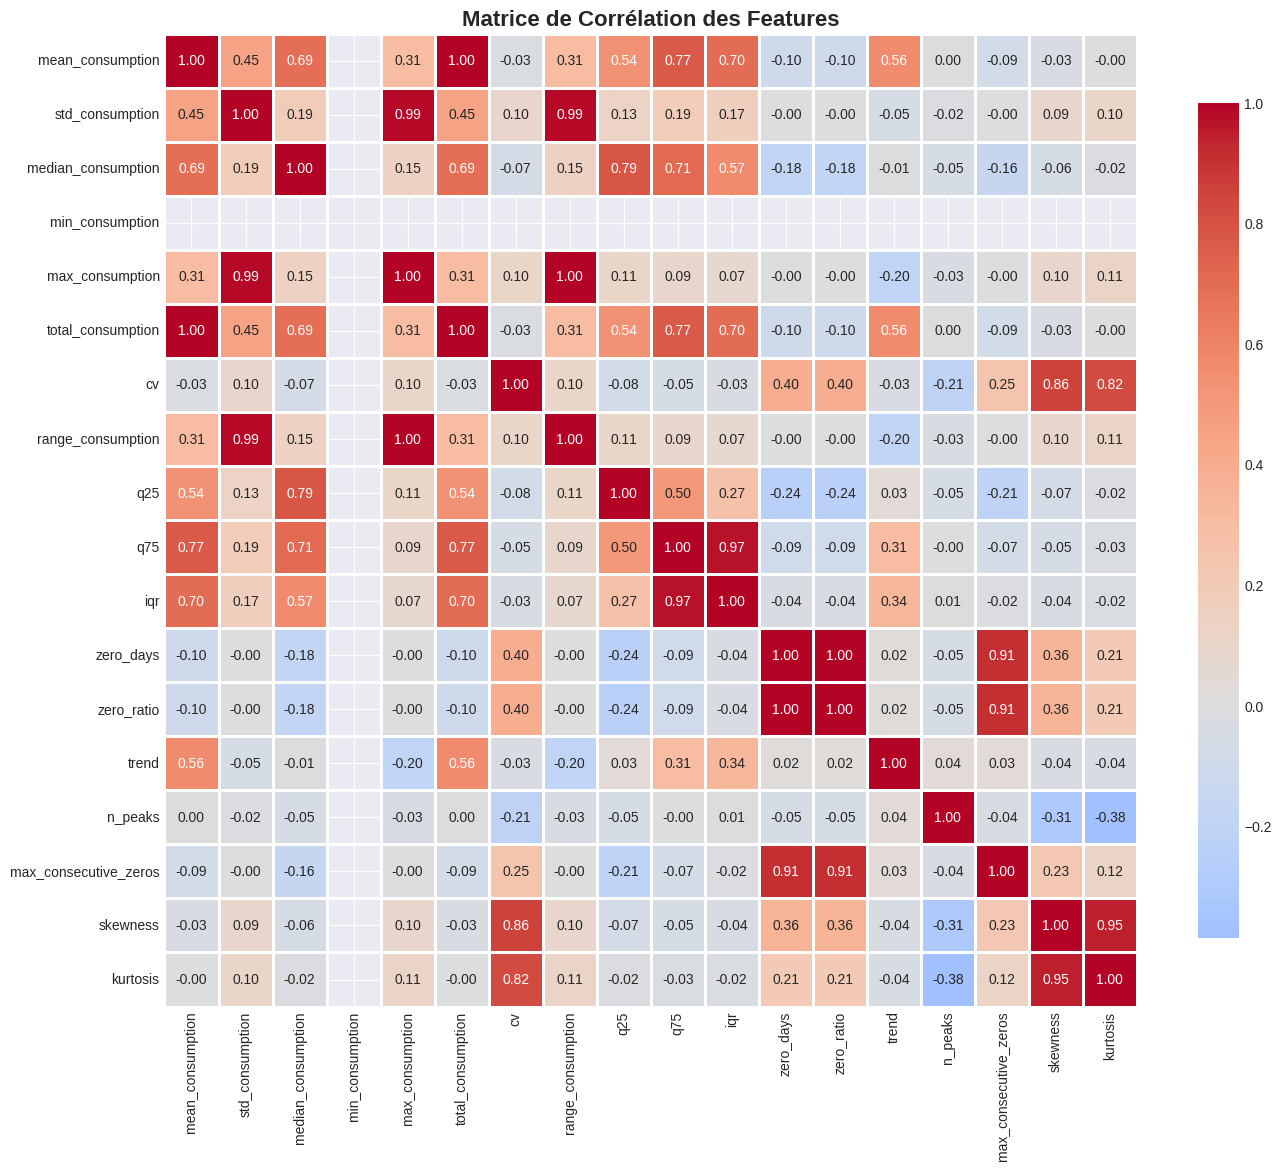

In [ ]:
print("🔗 ANALYSE DE CORRÉLATION ENTRE FEATURES\n")

# Sélectionner uniquement les features numériques
feature_cols = [col for col in df_features.columns if col not in ['CONS_NO', 'FLAG']]

# Calculer la matrice de corrélation
corr_matrix = df_features[feature_cols].corr()

# Visualisation
plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Matrice de Corrélation des Features', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Identifier les corrélations élevées (>0.9)
high_corr = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.9:
            high_corr.append((corr_matrix.columns[i], corr_matrix.columns[j], corr_matrix.iloc[i, j]))

print("\n⚠️ FEATURES FORTEMENT CORRÉLÉES (>0.9):")
for feat1, feat2, corr_val in high_corr:
    print(f"  • {feat1} ↔ {feat2}: {corr_val:.3f}")


⚠️ FEATURES FORTEMENT CORRÉLÉES (>0.9):
  • mean_consumption ↔ total_consumption: 1.000
  • std_consumption ↔ max_consumption: 0.985
  • std_consumption ↔ range_consumption: 0.985
  • max_consumption ↔ range_consumption: 1.000
  • q75 ↔ iqr: 0.969
  • zero_days ↔ zero_ratio: 1.000
  • zero_days ↔ max_consecutive_zeros: 0.907
  • zero_ratio ↔ max_consecutive_zeros: 0.907
  • skewness ↔ kurtosis: 0.948


In [ ]:
print(" SUPPRESSION DES FEATURES REDONDANTES\n")

# Features à supprimer (corrélation parfaite avec d'autres)
features_to_drop = ['total_consumption', 'range_consumption', 'min_consumption']
# total = mean × nombre_jours (redondant)
# range = max - min, et min = 0 partout (redondant)
# min = 0 partout après imputation (pas informatif)

df_features_clean = df_features.drop(columns=features_to_drop)
feature_cols_clean = [col for col in df_features_clean.columns if col not in ['CONS_NO', 'FLAG']]

print(f" Features conservées: {len(feature_cols_clean)}")
print(f"Liste: {feature_cols_clean}")

 SUPPRESSION DES FEATURES REDONDANTES

 Features conservées: 15
Liste: ['mean_consumption', 'std_consumption', 'median_consumption', 'max_consumption', 'cv', 'q25', 'q75', 'iqr', 'zero_days', 'zero_ratio', 'trend', 'n_peaks', 'max_consecutive_zeros', 'skewness', 'kurtosis']


In [ ]:
import os

# Créer le dossier 'data/processed' s'il n'existe pas
os.makedirs('data/processed', exist_ok=True)

# 1. Sauvegarder le dataset complet avec features
output_path = 'data/processed/electricity_fraud_features.csv'
df_features_clean.to_csv(output_path, index=False)
print(f"✅ Dataset sauvegardé : {output_path}")
print(f"   Lignes : {df_features_clean.shape[0]:,}")
print(f"   Colonnes : {df_features_clean.shape[1]} (dont {len(feature_cols_clean)} features)")

✅ Dataset sauvegardé : data/processed/electricity_fraud_features.csv
   Lignes : 42,372
   Colonnes : 17 (dont 15 features)


In [ ]:
# 2. Sauvegarder aussi la liste des features (pour référence)
with open('data/processed/feature_list.txt', 'w') as f:
    f.write("# LISTE DES FEATURES FINALES\n\n")
    f.write(f"Nombre total : {len(feature_cols_clean)}\n\n")
    for i, feature in enumerate(feature_cols_clean, 1):
        f.write(f"{i}. {feature}\n")
print(f"✅ Liste des features : data/processed/feature_list.txt")


✅ Liste des features : data/processed/feature_list.txt


###  Séparation X et y

In [ ]:
# Avant normalisation, remplacer NaN par 0
df_features_clean['skewness'] = df_features_clean['skewness'].fillna(0)
df_features_clean['kurtosis'] = df_features_clean['kurtosis'].fillna(0)


In [ ]:
print(" SÉPARATION FEATURES (X) ET TARGET (y)\n")

X = df_features_clean[feature_cols_clean].values
y = df_features_clean['FLAG'].values

print(f" X shape: {X.shape}")
print(f" y shape: {y.shape}")
print(f"\n Distribution de y:")
unique, counts = np.unique(y, return_counts=True)
for val, count in zip(unique, counts):
    print(f"  Classe {val}: {count} ({count/len(y)*100:.2f}%)")

 SÉPARATION FEATURES (X) ET TARGET (y)

 X shape: (42372, 15)
 y shape: (42372,)

 Distribution de y:
  Classe 0: 38757 (91.47%)
  Classe 1: 3615 (8.53%)


### Split Train/Test AVANT normalisation

In [ ]:
print(" DIVISION TRAIN/TEST (80/20)\n")

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # Garde la même proportion de classes dans train et test
)

print(f" X_train: {X_train.shape}")
print(f" X_test: {X_test.shape}")
print(f" y_train: {y_train.shape} - Fraudeurs: {sum(y_train)} ({sum(y_train)/len(y_train)*100:.2f}%)")
print(f" y_test: {y_test.shape} - Fraudeurs: {sum(y_test)} ({sum(y_test)/len(y_test)*100:.2f}%)")

 DIVISION TRAIN/TEST (80/20)

 X_train: (33897, 15)
 X_test: (8475, 15)
 y_train: (33897,) - Fraudeurs: 2892 (8.53%)
 y_test: (8475,) - Fraudeurs: 723 (8.53%)


### Normalisation avec StandardScaler

In [ ]:
print(" NORMALISATION DES DONNÉES\n")

from sklearn.preprocessing import StandardScaler

# Créer le scaler
scaler = StandardScaler()

# Fit sur train SEULEMENT (pour éviter le data leakage)
scaler.fit(X_train)

# Transform train et test
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(" Normalisation terminée!")
print(f"\n Avant normalisation (train) - Quelques stats:")
print(f"  Mean de la première feature: {X_train[:, 0].mean():.2f}")
print(f"  Std de la première feature: {X_train[:, 0].std():.2f}")

print(f"\n Après normalisation (train):")
print(f"  Mean de la première feature: {X_train_scaled[:, 0].mean():.2f}")
print(f"  Std de la première feature: {X_train_scaled[:, 0].std():.2f}")

 NORMALISATION DES DONNÉES

 Normalisation terminée!

 Avant normalisation (train) - Quelques stats:
  Mean de la première feature: 6.95
  Std de la première feature: 35.81

 Après normalisation (train):
  Mean de la première feature: -0.00
  Std de la première feature: 1.00


 VÉRIFICATION DE LA NORMALISATION

 Moyennes des features (doivent être ~0):
[-0.  0. -0.  0.  0.  0.  0.  0. -0. -0.  0.  0.  0. -0. -0.]

 Écarts-types des features (doivent être ~1):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


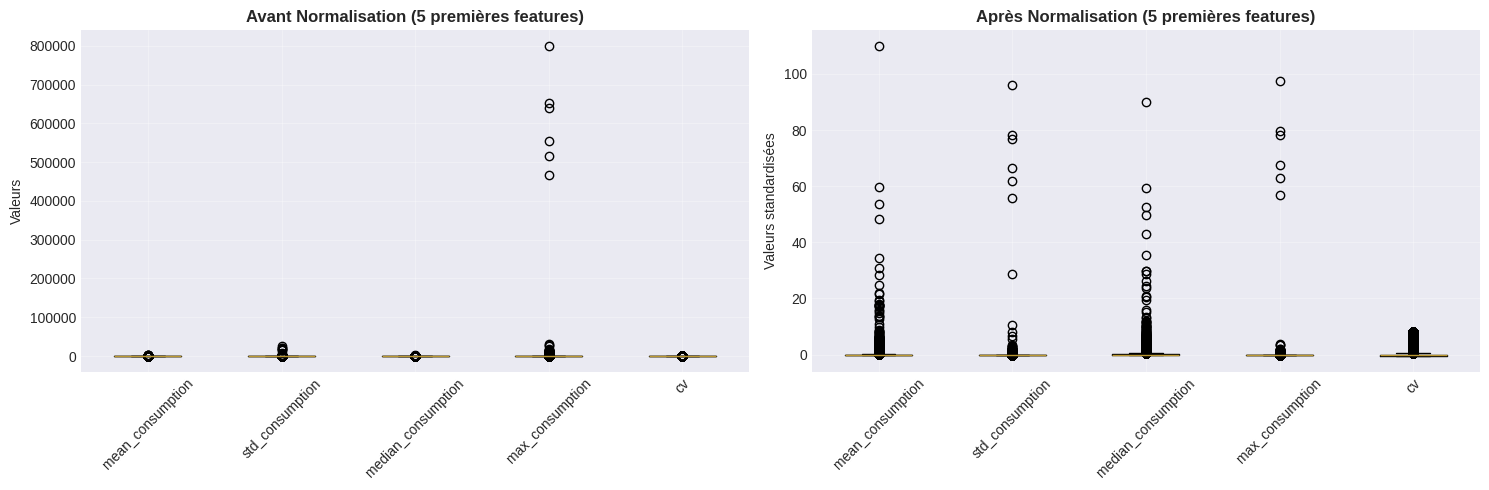

In [ ]:
# Vérification de la normalisation
print(" VÉRIFICATION DE LA NORMALISATION\n")

# Statistiques après normalisation
print(" Moyennes des features (doivent être ~0):")
print(np.mean(X_train_scaled, axis=0).round(10))

print("\n Écarts-types des features (doivent être ~1):")
print(np.std(X_train_scaled, axis=0).round(3))

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Avant normalisation
axes[0].boxplot(X_train[:, :5], labels=feature_cols_clean[:5])
axes[0].set_title('Avant Normalisation (5 premières features)', fontweight='bold')
axes[0].set_ylabel('Valeurs')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3)

# Après normalisation
axes[1].boxplot(X_train_scaled[:, :5], labels=feature_cols_clean[:5])
axes[1].set_title('Après Normalisation (5 premières features)', fontweight='bold')
axes[1].set_ylabel('Valeurs standardisées')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Etaoe 3 : GESTION DU DÉSÉQUILIBRE DES CLASSES
Problème : 91.47% normaux vs 8.53% fraudeurs

Solutions possibles :

-- SMOTE (Synthetic Minority Over-sampling Technique) : Crée des exemples synthétiques de fraudeurs

-- Undersampling : Réduit le nombre de clients normaux

-- Poids de classes : Donne plus d'importance aux fraudeurs dans la fonction de perte

-- Combinaison : SMOTE + Undersampling (SMOTE-ENN, SMOTE-Tomek)



###  Baseline sans gestion du déséquilibre

In [ ]:
print(" BASELINE : PERFORMANCES SANS GESTION DU DÉSÉQUILIBRE\n")

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Entraîner un modèle simple
rf_baseline = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_baseline.fit(X_train_scaled, y_train)

# Prédictions
y_pred_baseline = rf_baseline.predict(X_test_scaled)

# Évaluation
print(" RÉSULTATS BASELINE (sans gestion déséquilibre):\n")
print(classification_report(y_test, y_pred_baseline, target_names=['Normal', 'Fraudeur']))

# Matrice de confusion
cm_baseline = confusion_matrix(y_test, y_pred_baseline)
print("\n Matrice de Confusion:")
print(cm_baseline)
print(f"\nVrais Négatifs (TN): {cm_baseline[0,0]}")
print(f"Faux Positifs (FP): {cm_baseline[0,1]}")
print(f"Faux Négatifs (FN): {cm_baseline[1,0]}")
print(f"Vrais Positifs (TP): {cm_baseline[1,1]}")

 BASELINE : PERFORMANCES SANS GESTION DU DÉSÉQUILIBRE

 RÉSULTATS BASELINE (sans gestion déséquilibre):

              precision    recall  f1-score   support

      Normal       0.92      1.00      0.96      7752
    Fraudeur       0.59      0.07      0.12       723

    accuracy                           0.92      8475
   macro avg       0.76      0.53      0.54      8475
weighted avg       0.89      0.92      0.88      8475


 Matrice de Confusion:
[[7719   33]
 [ 675   48]]

Vrais Négatifs (TN): 7719
Faux Positifs (FP): 33
Faux Négatifs (FN): 675
Vrais Positifs (TP): 48


### Application de SMOTE

In [ ]:
print(" INSTALLATION DE IMBALANCED-LEARN\n")

# Si nécessaire (dans Colab, c'est déjà installé)
# !pip install imbalanced-learn

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN, SMOTETomek

print("✅ Bibliothèque imbalanced-learn importée!")

 INSTALLATION DE IMBALANCED-LEARN

✅ Bibliothèque imbalanced-learn importée!


In [ ]:
# ÉTAPE 1 : Nettoyage
df_features_clean[feature_cols_clean] = df_features_clean[feature_cols_clean].fillna(0)
df_features_clean[feature_cols_clean] = df_features_clean[feature_cols_clean].replace([np.inf, -np.inf], 0)

# ÉTAPE 2 : Création X, y
X = df_features_clean[feature_cols_clean].values
y = df_features_clean['FLAG'].values

# ÉTAPE 3 : Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ÉTAPE 4 : Normalisation
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_train_scaled = np.nan_to_num(X_train_scaled, nan=0.0, posinf=0.0, neginf=0.0)
X_test_scaled = np.nan_to_num(X_test_scaled, nan=0.0, posinf=0.0, neginf=0.0)

# ÉTAPE 5 : SMOTE
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("✅ SMOTE appliqué avec succès!")

✅ SMOTE appliqué avec succès!


In [ ]:
print(f"📊 AVANT SMOTE:")
print(f"  Train size: {X_train_scaled.shape[0]}")
print(f"  Fraudeurs: {sum(y_train)} ({sum(y_train)/len(y_train)*100:.2f}%)")
print(f"  Normaux: {len(y_train)-sum(y_train)} ({(len(y_train)-sum(y_train))/len(y_train)*100:.2f}%)")

print(f"\n📊 APRÈS SMOTE:")
print(f"  Train size: {X_train_smote.shape[0]}")
print(f"  Fraudeurs: {sum(y_train_smote)} ({sum(y_train_smote)/len(y_train_smote)*100:.2f}%)")
print(f"  Normaux: {len(y_train_smote)-sum(y_train_smote)} ({(len(y_train_smote)-sum(y_train_smote))/len(y_train_smote)*100:.2f}%)")

print(f"\n✅ Classes équilibrées! {sum(y_train_smote) - sum(y_train)} fraudeurs créés synthétiquement.")

📊 AVANT SMOTE:
  Train size: 33897
  Fraudeurs: 2892 (8.53%)
  Normaux: 31005 (91.47%)

📊 APRÈS SMOTE:
  Train size: 62010
  Fraudeurs: 31005 (50.00%)
  Normaux: 31005 (50.00%)

✅ Classes équilibrées! 28113 fraudeurs créés synthétiquement.


### Visualisation de l'effet de SMOTE (2D avec PCA)

📊 VISUALISATION DE L'EFFET DE SMOTE



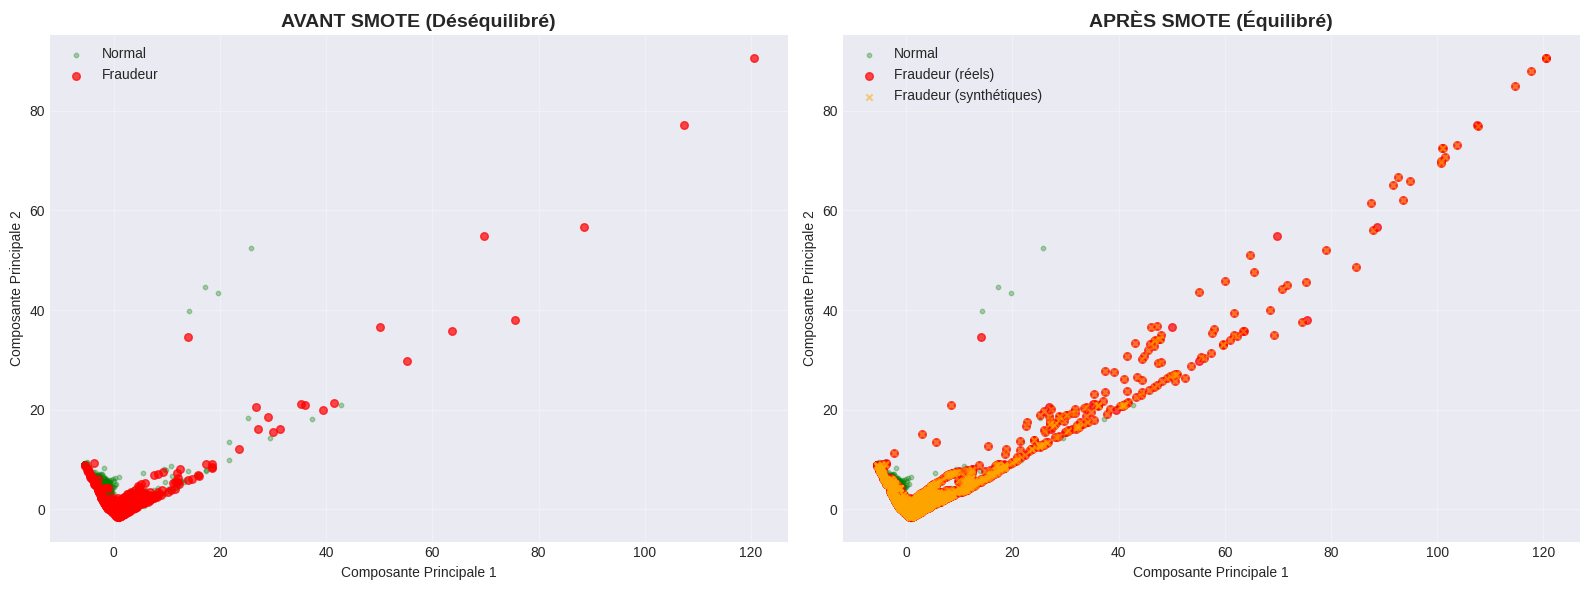

✅ Variance expliquée par les 2 composantes: 50.67%


In [ ]:
print("📊 VISUALISATION DE L'EFFET DE SMOTE\n")

from sklearn.decomposition import PCA

# Réduire à 2D pour visualiser
pca = PCA(n_components=2, random_state=42)

# Avant SMOTE
X_train_pca = pca.fit_transform(X_train_scaled)

# Après SMOTE
X_train_smote_pca = pca.transform(X_train_smote)

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Avant SMOTE
axes[0].scatter(X_train_pca[y_train==0, 0], X_train_pca[y_train==0, 1],
                alpha=0.3, s=10, c='green', label='Normal')
axes[0].scatter(X_train_pca[y_train==1, 0], X_train_pca[y_train==1, 1],
                alpha=0.7, s=30, c='red', label='Fraudeur')
axes[0].set_title('AVANT SMOTE (Déséquilibré)', fontweight='bold', fontsize=14)
axes[0].set_xlabel('Composante Principale 1')
axes[0].set_ylabel('Composante Principale 2')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Après SMOTE
axes[1].scatter(X_train_smote_pca[y_train_smote==0, 0], X_train_smote_pca[y_train_smote==0, 1],
                alpha=0.3, s=10, c='green', label='Normal')
axes[1].scatter(X_train_smote_pca[y_train_smote==1, 0], X_train_smote_pca[y_train_smote==1, 1],
                alpha=0.7, s=30, c='red', label='Fraudeur (réels)')
# Identifier les synthétiques (approximation)
n_synthetic = sum(y_train_smote) - sum(y_train)
axes[1].scatter(X_train_smote_pca[y_train_smote==1, 0][-n_synthetic:],
                X_train_smote_pca[y_train_smote==1, 1][-n_synthetic:],
                alpha=0.5, s=20, c='orange', marker='x', label='Fraudeur (synthétiques)')
axes[1].set_title('APRÈS SMOTE (Équilibré)', fontweight='bold', fontsize=14)
axes[1].set_xlabel('Composante Principale 1')
axes[1].set_ylabel('Composante Principale 2')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"✅ Variance expliquée par les 2 composantes: {sum(pca.explained_variance_ratio_)*100:.2f}%")

### Comparaison des méthodes de rééchantillonnage

 COMPARAISON DES MÉTHODES DE RÉÉCHANTILLONNAGE

      Méthode  Taille  Fraudeurs  Ratio_Fraudeurs_%
     Original   33897       2892           8.531728
        SMOTE   62010      31005          50.000000
Undersampling    5784       2892          50.000000
    SMOTE-ENN   49207      28240          57.390209
  SMOTE-Tomek   61274      30637          50.000000


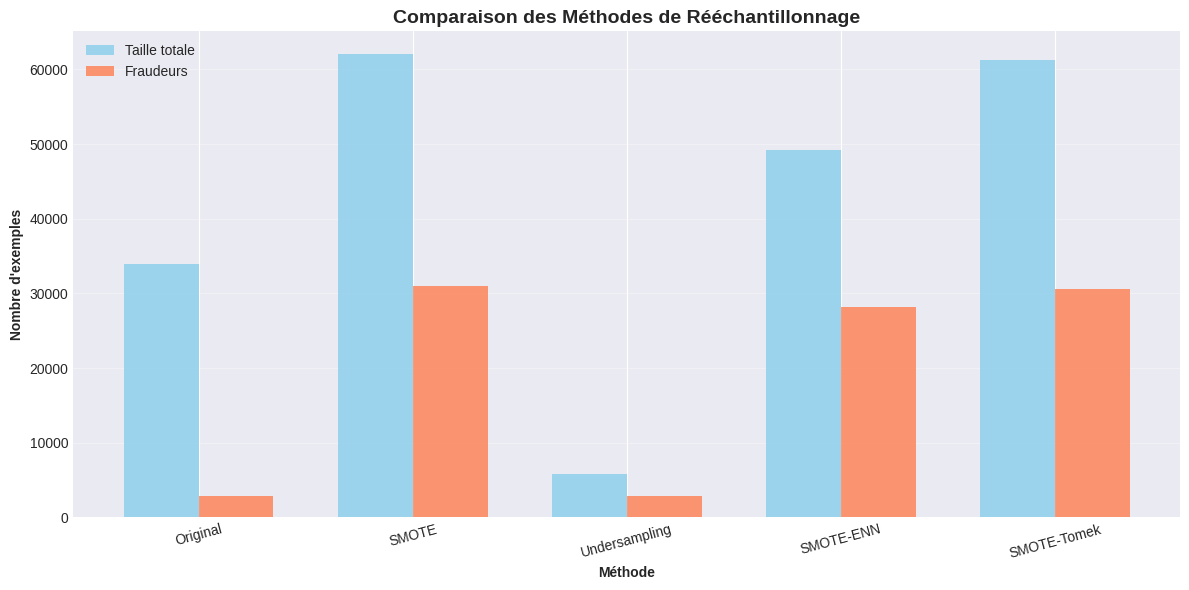

In [ ]:
print(" COMPARAISON DES MÉTHODES DE RÉÉCHANTILLONNAGE\n")

# 1. Undersampling
rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train_scaled, y_train)

# 2. SMOTE-ENN (combine SMOTE et Edited Nearest Neighbors)
smote_enn = SMOTEENN(random_state=42)
X_train_smoteenn, y_train_smoteenn = smote_enn.fit_resample(X_train_scaled, y_train)

# 3. SMOTE-Tomek (combine SMOTE et Tomek links)
smote_tomek = SMOTETomek(random_state=42)
X_train_smotetomek, y_train_smotetomek = smote_tomek.fit_resample(X_train_scaled, y_train)

# Résumé
methods = ['Original', 'SMOTE', 'Undersampling', 'SMOTE-ENN', 'SMOTE-Tomek']
sizes = [len(y_train), len(y_train_smote), len(y_train_under),
         len(y_train_smoteenn), len(y_train_smotetomek)]
frauds = [sum(y_train), sum(y_train_smote), sum(y_train_under),
          sum(y_train_smoteenn), sum(y_train_smotetomek)]

comparison_df = pd.DataFrame({
    'Méthode': methods,
    'Taille': sizes,
    'Fraudeurs': frauds,
    'Ratio_Fraudeurs_%': [f/s*100 for f, s in zip(frauds, sizes)]
})

print(comparison_df.to_string(index=False))

# Visualisation
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(methods))
width = 0.35

ax.bar(x - width/2, sizes, width, label='Taille totale', alpha=0.8, color='skyblue')
ax.bar(x + width/2, frauds, width, label='Fraudeurs', alpha=0.8, color='coral')

ax.set_xlabel('Méthode', fontweight='bold')
ax.set_ylabel('Nombre d\'exemples', fontweight='bold')
ax.set_title('Comparaison des Méthodes de Rééchantillonnage', fontweight='bold', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=15)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

##  Etape 4 :  DÉVELOPPEMENT DES MODÈLES ML


In [ ]:
print(" IMPORT DES ALGORITHMES ML\n")

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

print("✅ Algorithmes importés:")
print("  • Logistic Regression")
print("  • Random Forest")
print("  • Gradient Boosting")
print("  • XGBoost")
print("  • LightGBM")
print("  • SVM")
print("  • K-Nearest Neighbors")

 IMPORT DES ALGORITHMES ML

✅ Algorithmes importés:
  • Logistic Regression
  • Random Forest
  • Gradient Boosting
  • XGBoost
  • LightGBM
  • SVM
  • K-Nearest Neighbors


In [ ]:
print(" DÉFINITION DES MODÈLES\n")

# Dictionnaire de modèles
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss', use_label_encoder=False),
    'LightGBM': LGBMClassifier(n_estimators=100, random_state=42, verbose=-1),
    'SVM': SVC(kernel='rbf', random_state=42, probability=True),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

print(f"✅ {len(models)} modèles définis!")
for name in models.keys():
    print(f"  • {name}")

 DÉFINITION DES MODÈLES

✅ 7 modèles définis!
  • Logistic Regression
  • Random Forest
  • Gradient Boosting
  • XGBoost
  • LightGBM
  • SVM
  • KNN


In [ ]:
# Entraînement des modèles (sans SMOTE)
print(" ENTRAÎNEMENT DES MODÈLES (SANS SMOTE)\n")

import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

results_no_smote = []

for name, model in models.items():
    print(f"Training {name}...", end=' ')
    start_time = time.time()

    # Entraînement
    model.fit(X_train_scaled, y_train)

    # Prédictions
    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, 'predict_proba') else None

    # Métriques
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred_proba) if y_pred_proba is not None else 0

    train_time = time.time() - start_time

    results_no_smote.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUC': auc,
        'Time (s)': train_time
    })

    print(f"✅ ({train_time:.2f}s)")

# Affichage des résultats
results_no_smote_df = pd.DataFrame(results_no_smote)
results_no_smote_df = results_no_smote_df.sort_values('F1-Score', ascending=False)
print("\n📊 RÉSULTATS (SANS SMOTE):\n")
print(results_no_smote_df.to_string(index=False))

 ENTRAÎNEMENT DES MODÈLES (SANS SMOTE)

Training Logistic Regression... ✅ (0.39s)
Training Random Forest... ✅ (13.06s)
Training Gradient Boosting... ✅ (23.52s)
Training XGBoost... ✅ (1.41s)
Training LightGBM... ✅ (0.72s)
Training SVM... ✅ (218.11s)
Training KNN... ✅ (2.54s)

📊 RÉSULTATS (SANS SMOTE):

              Model  Accuracy  Precision   Recall  F1-Score      AUC   Time (s)
            XGBoost  0.917994   0.594595 0.121715  0.202067 0.778548   1.405446
           LightGBM  0.916578   0.590909 0.071923  0.128237 0.796252   0.717752
      Random Forest  0.916460   0.592593 0.066390  0.119403 0.769902  13.060437
                KNN  0.910914   0.378788 0.069156  0.116959 0.627530   2.539160
  Gradient Boosting  0.916578   0.637931 0.051176  0.094750 0.782427  23.523984
Logistic Regression  0.915988   0.648649 0.033195  0.063158 0.686563   0.393193
                SVM  0.915516   0.769231 0.013831  0.027174 0.633548 218.106276


In [ ]:
print("\n ENTRAÎNEMENT DES MODÈLES (AVEC SMOTE - SANS SVM)\n")

# Dictionnaire de modèles SANS SVM
models_fast = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss', use_label_encoder=False),
    'LightGBM': LGBMClassifier(n_estimators=100, random_state=42, verbose=-1),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

results_smote = []

for name, model in models_fast.items():
    print(f"Training {name}...", end=' ')
    start_time = time.time()

    # Entraînement sur données SMOTE
    model.fit(X_train_smote, y_train_smote)

    # Prédictions sur test (NON SMOTE !)
    y_pred = model.predict(X_test_scaled)
    y_pred_proba = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, 'predict_proba') else None

    # Métriques
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred_proba) if y_pred_proba is not None else 0

    train_time = time.time() - start_time

    results_smote.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUC': auc,
        'Time (s)': train_time
    })

    print(f"✅ ({train_time:.2f}s)")

# Affichage des résultats
results_smote_df = pd.DataFrame(results_smote)
results_smote_df = results_smote_df.sort_values('F1-Score', ascending=False)
print("\n📊 RÉSULTATS (AVEC SMOTE - SANS SVM):\n")
print(results_smote_df.to_string(index=False))


 ENTRAÎNEMENT DES MODÈLES (AVEC SMOTE - SANS SVM)

Training Logistic Regression... ✅ (2.50s)
Training Random Forest... ✅ (35.47s)
Training Gradient Boosting... ✅ (56.24s)
Training XGBoost... ✅ (1.00s)
Training LightGBM... ✅ (1.21s)
Training KNN... ✅ (3.38s)

📊 RÉSULTATS (AVEC SMOTE - SANS SVM):

              Model  Accuracy  Precision   Recall  F1-Score      AUC  Time (s)
           LightGBM  0.814867   0.247613 0.573997  0.345977 0.783328  1.205251
            XGBoost  0.836814   0.256996 0.482711  0.335416 0.771998  0.997642
      Random Forest  0.853569   0.269573 0.419087  0.328100 0.765644 35.467493
  Gradient Boosting  0.706195   0.178142 0.676349  0.282007 0.769612 56.243710
Logistic Regression  0.696047   0.159250 0.598893  0.251598 0.718798  2.495125
                KNN  0.741357   0.155649 0.459198  0.232493 0.651203  3.376969


In [ ]:
from sklearn.model_selection import GridSearchCV
import joblib

print("\n🔍 OPTIMISATION DES MODÈLES (GridSearchCV)\n")

# =====================
# 1️⃣ XGBOOST
# =====================
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss', use_label_encoder=False)

xgb_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

grid_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1,
    verbose=2
)

grid_xgb.fit(X_train_smote, y_train_smote)
best_xgb = grid_xgb.best_estimator_

print("\n✅ Meilleurs hyperparamètres XGBoost :")
print(grid_xgb.best_params_)


🔍 OPTIMISATION DES MODÈLES (GridSearchCV)

Fitting 3 folds for each of 72 candidates, totalling 216 fits

✅ Meilleurs hyperparamètres XGBoost :
{'colsample_bytree': 1.0, 'learning_rate': 0.2, 'max_depth': 7, 'n_estimators': 200, 'subsample': 1.0}


In [ ]:
# Évaluation
y_pred_xgb = best_xgb.predict(X_test_scaled)
y_pred_proba_xgb = best_xgb.predict_proba(X_test_scaled)[:, 1]

print("\n📊 Rapport de classification XGBoost :")
print(classification_report(y_test, y_pred_xgb))
print("AUC :", roc_auc_score(y_test, y_pred_proba_xgb))



📊 Rapport de classification XGBoost :
              precision    recall  f1-score   support

           0       0.94      0.90      0.92      7752
           1       0.29      0.43      0.35       723

    accuracy                           0.86      8475
   macro avg       0.62      0.67      0.64      8475
weighted avg       0.89      0.86      0.87      8475

AUC : 0.7698646813315121


In [ ]:
# Sauvegarde du modèle
joblib.dump(best_xgb, "best_xgboost_model.pkl")
print("💾 Modèle XGBoost sauvegardé sous : best_xgboost_model.pkl")

💾 Modèle XGBoost sauvegardé sous : best_xgboost_model.pkl


In [ ]:
# 2️⃣ LIGHTGBM
# =====================
lgbm_model = LGBMClassifier(random_state=42)

lgbm_param_grid = {
    'n_estimators': [100, 200],
    'num_leaves': [31, 63, 127],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

grid_lgbm = GridSearchCV(
    estimator=lgbm_model,
    param_grid=lgbm_param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1,
    verbose=2
)

grid_lgbm.fit(X_train_smote, y_train_smote)
best_lgbm = grid_lgbm.best_estimator_

print("\n✅ Meilleurs hyperparamètres LightGBM :")
print(grid_lgbm.best_params_)

Fitting 3 folds for each of 72 candidates, totalling 216 fits

✅ Meilleurs hyperparamètres LightGBM :
{'colsample_bytree': 1.0, 'learning_rate': 0.2, 'n_estimators': 200, 'num_leaves': 127, 'subsample': 0.8}


In [ ]:
# Évaluation
y_pred_lgbm = best_lgbm.predict(X_test_scaled)
y_pred_proba_lgbm = best_lgbm.predict_proba(X_test_scaled)[:, 1]

print("\n📊 Rapport de classification LightGBM :")
print(classification_report(y_test, y_pred_lgbm))
print("AUC :", roc_auc_score(y_test, y_pred_proba_lgbm))



📊 Rapport de classification LightGBM :
              precision    recall  f1-score   support

           0       0.93      0.95      0.94      7752
           1       0.37      0.29      0.32       723

    accuracy                           0.90      8475
   macro avg       0.65      0.62      0.63      8475
weighted avg       0.89      0.90      0.89      8475

AUC : 0.7516099891947753


In [ ]:
# Sauvegarde du modèle
joblib.dump(best_lgbm, "best_lightgbm_model.pkl")
print("💾 Modèle LightGBM sauvegardé sous : best_lightgbm_model.pkl")

💾 Modèle LightGBM sauvegardé sous : best_lightgbm_model.pkl


In [ ]:
import joblib

# Sauvegarde du scaler
joblib.dump(scaler, "scaler2.pkl")
print("💾 Scaler sauvegardé sous : scaler.pkl")


💾 Scaler sauvegardé sous : scaler.pkl
